# Notebook 03b — Non-IID Experiments on CIFAR-100
**DS Lab 2 | Membership Inference Attacks in Federated Learning**

This notebook evaluates the impact of Non-IID data partitioning on membership
inference attack success for **CIFAR-100 only**.

**What this notebook does:**
- Runs FL + MIA under IID partitioning (baseline)
- Runs FL + MIA under Non-IID partitioning (50 classes per client)
- Compares attack AUC between IID and Non-IID
- Produces comparison plots and saves results

**Run Notebook 03a first for CIFAR-10 results.**

**Configuration:** 5 clients | 10 rounds | 3 local epochs
This notebook is **fully self-contained** — no file uploads needed.


## 1. Imports & Configuration


In [1]:
import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import json, os, gc

from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    roc_auc_score, roc_curve
)
import matplotlib.pyplot as plt

NUM_CLIENTS            = 5
NUM_ROUNDS             = 10
LOCAL_EPOCHS           = 3
BATCH_SIZE             = 64
LEARNING_RATE          = 0.001
NUM_CLASSES            = 100
RANDOM_SEED            = 42
CLASSES_PER_CLIENT     = 50  # each client gets 50 out of 100 classes

np.random.seed(RANDOM_SEED)
tf.random.set_seed(RANDOM_SEED)
gc.collect()
tf.keras.backend.clear_session()

OUTPUT_DIR = '/content/outputs'
os.makedirs(OUTPUT_DIR, exist_ok=True)

print(f'TensorFlow : {tf.__version__}')
print(f'GPU        : {tf.config.list_physical_devices("GPU")}')
print(f'Config     : {NUM_CLIENTS} clients | {NUM_ROUNDS} rounds | {LOCAL_EPOCHS} local epochs')
print(f'Non-IID    : {CLASSES_PER_CLIENT} classes per client')


TensorFlow : 2.19.0
GPU        : [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Config     : 5 clients | 10 rounds | 3 local epochs
Non-IID    : 50 classes per client


## 2. Load CIFAR-100


In [2]:
(x_train, y_train), (x_test, y_test) = keras.datasets.cifar100.load_data(label_mode='fine')
x_train = x_train.astype('float32') / 255.0
x_test  = x_test.astype('float32')  / 255.0
y_train = y_train.flatten()
y_test  = y_test.flatten()

print(f'Training set : {x_train.shape}')
print(f'Test set     : {x_test.shape}')
print(f'Classes      : {len(np.unique(y_train))}')


169001437/169001437 ━━━━━━━━━━━━━━━━━━━━ 13s 0us/step
Training set : (50000, 32, 32, 3)
Test set     : (10000, 32, 32, 3)
Classes      : 100


## 3. Partitioning & Helper Functions


In [3]:
def partition_data_iid(x, y, num_clients, seed=42):
    rng     = np.random.default_rng(seed)
    indices = rng.permutation(len(x))
    splits  = np.array_split(indices, num_clients)
    client_data    = [(x[idx], y[idx]) for idx in splits]
    client_indices = [idx.tolist() for idx in splits]
    return client_data, client_indices


def partition_data_noniid(x, y, num_clients, classes_per_client=50, seed=42):
    num_classes = len(np.unique(y))
    rng = np.random.default_rng(seed)
    class_indices = {c: rng.permutation(np.where(y == c)[0]) for c in range(num_classes)}
    client_data    = []
    client_indices = []
    for i in range(num_clients):
        assigned = [(i * classes_per_client + j) % num_classes for j in range(classes_per_client)]
        idx = np.concatenate([class_indices[c] for c in assigned])
        client_data.append((x[idx], y[idx]))
        client_indices.append(idx.tolist())
        print(f'  Client {i+1}: {len(idx):>6} samples | {len(np.unique(y[idx]))} classes')
    return client_data, client_indices


def build_model(num_classes=100, learning_rate=0.001):
    model = keras.Sequential([
        layers.Input(shape=(32, 32, 3)),
        layers.Conv2D(32, (3,3), activation='relu', padding='same'),
        layers.MaxPooling2D(),
        layers.Conv2D(64, (3,3), activation='relu', padding='same'),
        layers.MaxPooling2D(),
        layers.Flatten(),
        layers.Dense(128, activation='relu'),
        layers.Dropout(0.3),
        layers.Dense(num_classes, activation='softmax'),
    ])
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )
    return model


def fedavg_aggregate(client_weights, client_sizes):
    total = sum(client_sizes)
    return [
        sum((s / total) * w for w, s in zip(layer_ws, client_sizes))
        for layer_ws in zip(*client_weights)
    ]


def local_train(global_weights, x_c, y_c, local_epochs, batch_size, lr):
    m = build_model(num_classes=NUM_CLASSES, learning_rate=lr)
    m.set_weights(global_weights)
    m.fit(x_c, y_c, epochs=local_epochs, batch_size=batch_size, verbose=0)
    return m.get_weights()


def run_fl_and_attack(client_data, member_idx, num_rounds, local_epochs,
                      batch_size, lr, n_attack=3000, seed=42):
    gc.collect()
    tf.keras.backend.clear_session()
    client_sizes = [len(xc) for xc, _ in client_data]
    gm = build_model(num_classes=NUM_CLASSES, learning_rate=lr)
    gw = gm.get_weights()
    round_accs = []
    for r in range(num_rounds):
        cw_list = [local_train(gw, xc, yc, local_epochs, batch_size, lr)
                   for xc, yc in client_data]
        gw = fedavg_aggregate(cw_list, client_sizes)
        gm.set_weights(gw)
        _, acc = gm.evaluate(x_test, y_test, verbose=0)
        round_accs.append(acc)
        print(f'  Round {r+1:02d}/{num_rounds} | Acc: {acc:.4f}')

    rng    = np.random.default_rng(seed)
    n      = min(n_attack, len(member_idx), len(x_test))
    m_idx  = rng.choice(member_idx,  size=n, replace=False)
    nm_idx = rng.choice(len(x_test), size=n, replace=False)
    m_probs  = gm.predict(x_train[m_idx],  batch_size=256, verbose=0)
    nm_probs = gm.predict(x_test[nm_idx],  batch_size=256, verbose=0)
    X_atk = np.vstack([m_probs, nm_probs])
    y_atk = np.array([1]*n + [0]*n)

    epsilon = 1e-10
    pred_classes = np.argmax(X_atk, axis=1)
    oh = np.zeros_like(X_atk)
    for i, c in enumerate(pred_classes):
        oh[i, c] = 1
    loss_scores = -(-np.sum(oh * np.log(X_atk + epsilon), axis=1))
    loss_auc    = roc_auc_score(y_atk, loss_scores)

    X_tr, X_te, y_tr, y_te = train_test_split(
        X_atk, y_atk, test_size=0.3, random_state=seed, stratify=y_atk)
    attacker = LogisticRegression(max_iter=1000, random_state=seed)
    attacker.fit(X_tr, y_tr)
    y_pred      = attacker.predict(X_te)
    y_pred_prob = attacker.predict_proba(X_te)[:, 1]
    fpr, tpr, _ = roc_curve(y_te, y_pred_prob)
    lr_auc      = roc_auc_score(y_te, y_pred_prob)
    lr_acc      = accuracy_score(y_te, y_pred)
    lr_recall   = recall_score(y_te, y_pred)

    del gm, cw_list, m_probs, nm_probs, X_atk
    gc.collect()

    return {
        'global_acc' : round_accs[-1],
        'round_accs' : round_accs,
        'lr_auc'     : lr_auc,
        'lr_acc'     : lr_acc,
        'lr_recall'  : lr_recall,
        'loss_auc'   : loss_auc,
        'fpr'        : fpr,
        'tpr'        : tpr,
    }


print('All functions defined.')


All functions defined.


## 4. CIFAR-100 — IID Baseline


In [4]:
print('=' * 55)
print('CIFAR-100 — IID Partitioning')
print('=' * 55)
iid_data, iid_idx = partition_data_iid(x_train, y_train, NUM_CLIENTS, RANDOM_SEED)
iid_members = [i for sub in iid_idx for i in sub]
for i, (xc, yc) in enumerate(iid_data):
    print(f'  Client {i+1}: {xc.shape[0]} samples | {len(np.unique(yc))} classes')

print('\nRunning FL + attack...')
iid_results = run_fl_and_attack(
    iid_data, iid_members,
    NUM_ROUNDS, LOCAL_EPOCHS, BATCH_SIZE, LEARNING_RATE
)
print(f'\n  Global accuracy : {iid_results["global_acc"]:.4f}')
print(f'  LR attack AUC   : {iid_results["lr_auc"]:.4f}')
print(f'  Loss attack AUC : {iid_results["loss_auc"]:.4f}')


CIFAR-100 — IID Partitioning
  Client 1: 10000 samples | 100 classes
  Client 2: 10000 samples | 100 classes
  Client 3: 10000 samples | 100 classes
  Client 4: 10000 samples | 100 classes
  Client 5: 10000 samples | 100 classes

Running FL + attack...
  Round 01/10 | Acc: 0.1126
  Round 02/10 | Acc: 0.2437
  Round 03/10 | Acc: 0.2935
  Round 04/10 | Acc: 0.3231
  Round 05/10 | Acc: 0.3430
  Round 06/10 | Acc: 0.3577
  Round 07/10 | Acc: 0.3625
  Round 08/10 | Acc: 0.3778
  Round 09/10 | Acc: 0.3765
  Round 10/10 | Acc: 0.3759

  Global accuracy : 0.3759
  LR attack AUC   : 0.5407
  Loss attack AUC : 0.5606


## 5. CIFAR-100 — Non-IID


In [5]:
print('=' * 55)
print(f'CIFAR-100 — Non-IID ({CLASSES_PER_CLIENT} classes per client)')
print('=' * 55)
noniid_data, noniid_idx = partition_data_noniid(
    x_train, y_train, NUM_CLIENTS,
    classes_per_client=CLASSES_PER_CLIENT,
    seed=RANDOM_SEED
)
noniid_members = [i for sub in noniid_idx for i in sub]

print('\nRunning FL + attack...')
noniid_results = run_fl_and_attack(
    noniid_data, noniid_members,
    NUM_ROUNDS, LOCAL_EPOCHS, BATCH_SIZE, LEARNING_RATE
)
print(f'\n  Global accuracy : {noniid_results["global_acc"]:.4f}')
print(f'  LR attack AUC   : {noniid_results["lr_auc"]:.4f}')
print(f'  Loss attack AUC : {noniid_results["loss_auc"]:.4f}')


CIFAR-100 — Non-IID (50 classes per client)
  Client 1:  25000 samples | 50 classes
  Client 2:  25000 samples | 50 classes
  Client 3:  25000 samples | 50 classes
  Client 4:  25000 samples | 50 classes
  Client 5:  25000 samples | 50 classes

Running FL + attack...
  Round 01/10 | Acc: 0.1023
  Round 02/10 | Acc: 0.1552
  Round 03/10 | Acc: 0.1996
  Round 04/10 | Acc: 0.2307
  Round 05/10 | Acc: 0.2394
  Round 06/10 | Acc: 0.2419
  Round 07/10 | Acc: 0.2500
  Round 08/10 | Acc: 0.2522
  Round 09/10 | Acc: 0.2515
  Round 10/10 | Acc: 0.2496

  Global accuracy : 0.2496
  LR attack AUC   : 0.5426
  Loss attack AUC : 0.5636


## 6. IID vs Non-IID — Results & Plots


════════════════════════════════════════════════════════════
CIFAR-100 — IID vs Non-IID Comparison
════════════════════════════════════════════════════════════
Condition                   Global Acc     LR AUC   Loss AUC
------------------------------------------------------------
IID                             0.3759     0.5407     0.5606
Non-IID (50 classes)            0.2496     0.5426     0.5636
════════════════════════════════════════════════════════════
LR AUC increase  : +0.0019
Loss AUC increase: +0.0030
Random-chance baseline = 0.50


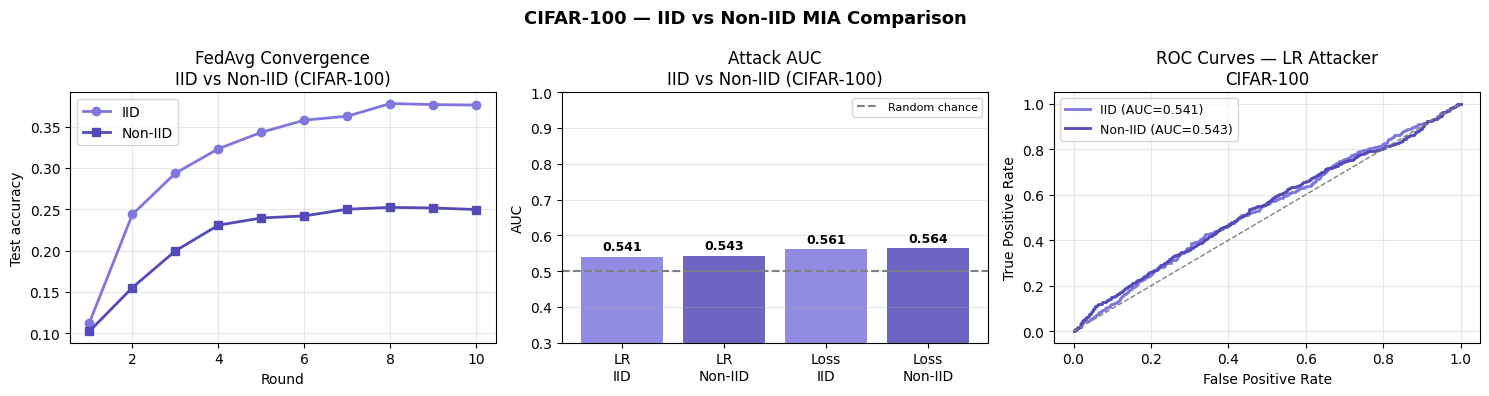

In [6]:
# ── Plot style ───────────────────────────────────────────────────────────────
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np

plt.rcParams.update({
    'font.family': 'DejaVu Sans', 'font.size': 12,
    'axes.titlesize': 14, 'axes.titleweight': 'bold',
    'axes.labelsize': 12, 'axes.spines.top': False,
    'axes.spines.right': False, 'axes.grid': True,
    'grid.alpha': 0.25, 'grid.linestyle': '--',
    'figure.dpi': 150, 'savefig.dpi': 150,
    'savefig.bbox': 'tight', 'savefig.facecolor': 'white',
})
TEAL='#0D9488'; NAVY='#0D1B2A'; BLUE='#378ADD'
RED='#EF4444'; GOLD='#F59E0B'; SLATE='#64748B'
RANDOM_LINE = dict(color='#9CA3AF', linestyle='--', linewidth=1.4, label='Random chance (0.50)')

# ── Figure 1: Convergence ─────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(10, 5.5))
ax.plot(range(1, NUM_ROUNDS+1), iid_results['round_accs'],
        marker='o', linewidth=2.5, color='#7C3AED', markersize=8, label='IID')
ax.plot(range(1, NUM_ROUNDS+1), noniid_results['round_accs'],
        marker='s', linewidth=2.5, color='#4C1D95', markersize=8, label='Non-IID (50/100 classes)')
ax.fill_between(range(1, NUM_ROUNDS+1), iid_results['round_accs'], alpha=0.06, color='#7C3AED')
ax.fill_between(range(1, NUM_ROUNDS+1), noniid_results['round_accs'], alpha=0.06, color='#4C1D95')
ax.set_xlabel('Federated Round', fontsize=13)
ax.set_ylabel('Global Test Accuracy', fontsize=13)
ax.set_title('FedAvg Convergence — IID vs Non-IID\nCIFAR-100 (5 clients, 10 rounds)',
             fontsize=14, fontweight='bold')
ax.legend(fontsize=12)
ax.set_xticks(range(1, NUM_ROUNDS+1))
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'cifar100_noniid_convergence.png'), dpi=150, bbox_inches='tight')
plt.show()

# ── Figure 2: Annotated grouped bar ──────────────────────────────────────────
conditions = ['IID\nLR AUC', 'Non-IID\nLR AUC', 'IID\nLoss AUC', 'Non-IID\nLoss AUC']
values     = [iid_results['lr_auc'], noniid_results['lr_auc'],
              iid_results['loss_auc'], noniid_results['loss_auc']]
bar_colors = ['#7C3AED', '#6D28D9', BLUE, '#1D4ED8']

fig, ax = plt.subplots(figsize=(11, 6.5))
x = np.arange(len(conditions))
bars = ax.bar(x, values, color=bar_colors, alpha=0.85, width=0.5, edgecolor='white')
for bar, v in zip(bars, values):
    ax.text(bar.get_x() + bar.get_width()/2, v + 0.003,
            f'{v:.4f}', ha='center', va='bottom', fontsize=12, fontweight='bold',
            color=bar.get_facecolor())

for (i_idx, ni_idx) in [(0,1),(2,3)]:
    delta = values[ni_idx] - values[i_idx]
    y_ann = max(values[i_idx], values[ni_idx]) + 0.018
    ax.annotate('', xy=(x[ni_idx], y_ann), xytext=(x[i_idx], y_ann),
                arrowprops=dict(arrowstyle='<->', color='#374151', lw=2.0))
    sign = '+' if delta > 0 else ''
    ax.text((x[i_idx]+x[ni_idx])/2, y_ann+0.003,
            f'{sign}{delta:.4f}', ha='center', fontsize=11, fontweight='bold',
            color=SLATE)

ax.axhline(0.50, **RANDOM_LINE)
ax.set_xticks(x)
ax.set_xticklabels(conditions, fontsize=11)
ax.set_ylabel('Attack AUC', fontsize=13)
ax.set_title('RQ4: IID vs Non-IID — Attack Success Comparison\nCIFAR-100 (low Non-IID: 50 out of 100 classes per client)',
             fontsize=14, fontweight='bold')
ax.set_ylim(0.44, 0.62)
ax.legend(fontsize=11)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'cifar100_noniid_comparison.png'), dpi=150, bbox_inches='tight')
plt.show()

print(f"IID  — LR: {iid_results['lr_auc']:.4f}  Loss: {iid_results['loss_auc']:.4f}")
print(f"NonIID — LR: {noniid_results['lr_auc']:.4f}  Loss: {noniid_results['loss_auc']:.4f}")
print(f"Delta Loss AUC: {noniid_results['loss_auc']-iid_results['loss_auc']:+.4f}")


## 7. Save & Download


In [7]:
results = {
    'cifar100_iid'    : {k: float(v) if not isinstance(v, list) else v
                         for k, v in iid_results.items() if k not in ['fpr','tpr']},
    'cifar100_noniid' : {k: float(v) if not isinstance(v, list) else v
                         for k, v in noniid_results.items() if k not in ['fpr','tpr']},
}
with open(os.path.join(OUTPUT_DIR, 'cifar100_noniid_results.json'), 'w') as f:
    json.dump(results, f, indent=2)

from google.colab import files
files.download(os.path.join(OUTPUT_DIR, 'cifar100_noniid_results.json'))
files.download(os.path.join(OUTPUT_DIR, 'cifar100_noniid_comparison.png'))
print('All done!')


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

All done!
